In [4]:
import pandas as pd
import numpy as nd
import seaborn as sn
import matplotlib 




In [5]:
train = pd.read_csv("data/raw/kaggle_train_set.csv")
train.head()

,OverallQual,GrLivArea,TotalBsmtSF,1stFlrSF,YearBuilt,YearRemodAdd,GarageCars,GarageArea,FullBath,TotRmsAbvGrd,KitchenQual,Fireplaces,LotArea,Neighborhood,ExterQual,SalePrice
0,7,1710,856,856,2003,2003,2,548,2,8,Gd,0,8450,CollgCr,Gd,208500
1,6,1262,1262,1262,1976,1976,2,460,2,6,TA,1,9600,Veenker,TA,181500
2,7,1786,920,920,2001,2002,2,608,2,6,Gd,1,11250,CollgCr,Gd,223500
3,8,1694,1686,1694,2004,2005,2,636,2,7,Gd,1,10084,Somerst,Gd,307000
4,7,1774,952,1022,1931,1950,2,468,2,8,TA,2,6120,OldTown,TA,129900


In [6]:
print(f"Nombre de lignes : {train.shape[0]}")
print(f"Nombre de colonnes : {train.shape[1]}")

valeurs_manquantes = train.isna().sum()
valeurs_manquantes[valeurs_manquantes > 0].sort_values(ascending=False)

Nombre de lignes : 1180
Nombre de colonnes : 16


Series([], dtype: int64)

count      1180.000000
mean     179822.169492
std       79703.346024
min       34900.000000
25%      128800.000000
50%      161250.000000
75%      212000.000000
max      755000.000000
Name: SalePrice, dtype: float64

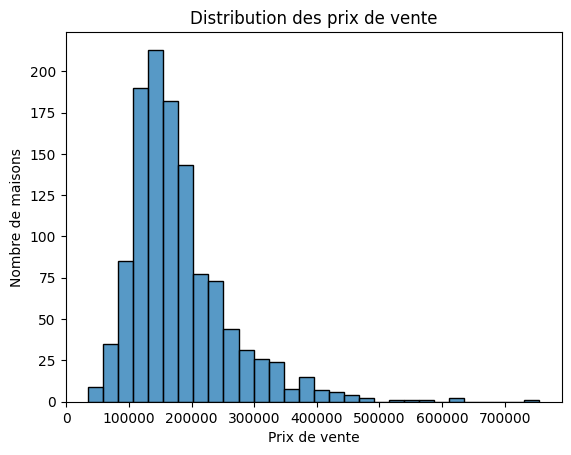

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

display(train["SalePrice"].describe())

sns.histplot(data=train, x="SalePrice", bins=30)
plt.title("Distribution des prix de vente")
plt.xlabel("Prix de vente")
plt.ylabel("Nombre de maisons")
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = train.drop(columns="SalePrice")
y = train["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Entraînement :", X_train.shape)
print("Validation :", X_val.shape)

Entraînement : (944, 15)
Validation : (236, 15)


count       944.00
mean     180157.95
std       79876.29
min       34900.00
25%      129000.00
50%      162000.00
75%      212000.00
max      755000.00
Name: SalePrice, dtype: float64

Asymétrie du prix : 1.78
Asymétrie du logarithme du prix : 0.07


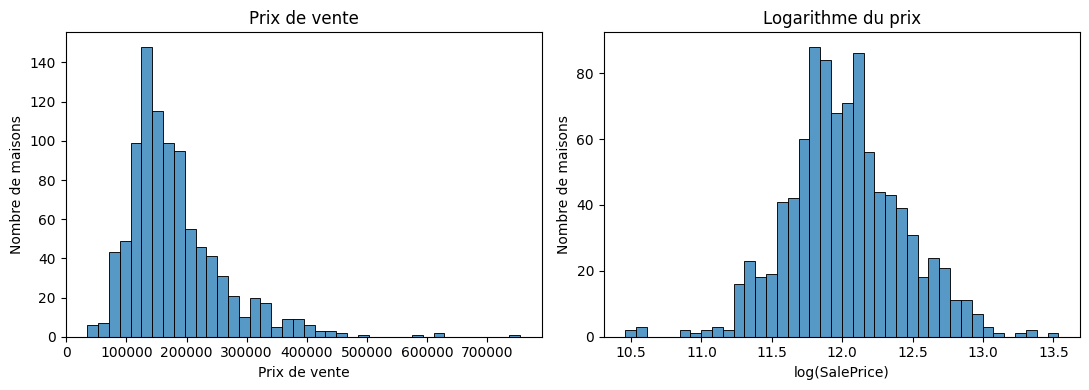

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

log_prix = np.log(y_train)

display(y_train.describe().round(2))
print(f"Asymétrie du prix : {y_train.skew():.2f}")
print(f"Asymétrie du logarithme du prix : {log_prix.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(x=y_train, bins=40, ax=axes[0])
axes[0].set(title="Prix de vente", xlabel="Prix de vente", ylabel="Nombre de maisons")

sns.histplot(x=log_prix, bins=40, ax=axes[1])
axes[1].set(title="Logarithme du prix", xlabel="log(SalePrice)", ylabel="Nombre de maisons")

fig.tight_layout()
plt.show()

In [10]:
colonnes_numeriques = X_train.select_dtypes(include="number").columns.tolist()
colonnes_categorielles = X_train.select_dtypes(exclude="number").columns.tolist()

print("Colonnes numériques :", colonnes_numeriques)
print("Colonnes catégorielles :", colonnes_categorielles)
print("Nombre de valeurs manquantes :", X_train.isna().sum().sum())

Colonnes numériques : ['OverallQual', 'GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageCars', 'GarageArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'LotArea']
Colonnes catégorielles : ['KitchenQual', 'Neighborhood', 'ExterQual']
Nombre de valeurs manquantes : 0


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pretraitement = ColumnTransformer(
    transformers=[
        ("numerique", StandardScaler(), colonnes_numeriques),
        ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
    ]
)

pretraitement

,transformers,"[('numerique', ...), ('categoriel', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


In [12]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

modele_ridge = Pipeline([
    ("pretraitement", pretraitement),
    ("regression", Ridge(alpha=1.0)),
])

modele_ridge.fit(X_train, y_train)

/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,steps,"[('pretraitement', ...), ('regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerique', ...), ('categoriel', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [13]:
encodeur = modele_ridge.named_steps["pretraitement"].named_transformers_["categoriel"]

exemple = X_train[colonnes_categorielles].head()
valeurs_encodees = encodeur.transform(exemple)

tableau_encode = pd.DataFrame(
    valeurs_encodees.toarray(),
    columns=encodeur.get_feature_names_out(colonnes_categorielles),
    index=exemple.index,
)

display(exemple)
display(tableau_encode.astype(int))

,KitchenQual,Neighborhood,ExterQual
296,Gd,NAmes,TA
599,TA,SawyerW,TA
711,Gd,NAmes,Gd
274,TA,MeadowV,TA
362,TA,OldTown,TA


,KitchenQual_Ex,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Neighborhood_Blmngtn,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,...,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA
296,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
599,0,0,0,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
711,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
274,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
362,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [14]:
from sklearn.metrics import mean_absolute_error

prix_median = y_train.median()
mae_reference = (y_val - prix_median).abs().mean()

predictions_ridge = modele_ridge.predict(X_val)
mae_ridge = mean_absolute_error(y_val, predictions_ridge)

print(f"MAE de la référence : {mae_reference:,.2f}")
print(f"MAE de Ridge        : {mae_ridge:,.2f}")

MAE de la référence : 54,691.43
MAE de Ridge        : 20,936.76


/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


## Premiers résultats

Le modèle Ridge (`alpha=1.0`) a été entraîné sur 944 maisons.
Les deux méthodes ont été évaluées sur les mêmes 236 maisons de validation.

| Méthode | Erreur absolue moyenne (MAE) |
|---|---:|
| Référence basée sur le prix médian d’entraînement | 54 691,43 |
| Régression Ridge | 20 936,76 |

Sur ce jeu de validation, Ridge réduit la MAE de 61,7 % par rapport à la référence.

In [15]:
import numpy as np

X_val_prepare = modele_ridge.named_steps["pretraitement"].transform(X_val)
if hasattr(X_val_prepare, "toarray"):
    X_val_prepare = X_val_prepare.toarray()

ridge = modele_ridge.named_steps["regression"]
predictions_verifiees = (X_val_prepare * ridge.coef_).sum(axis=1) + ridge.intercept_

print("Toutes les prédictions sont finies :", np.isfinite(predictions_ridge).all())
print("Les deux calculs concordent :", np.allclose(predictions_ridge, predictions_verifiees))

Toutes les prédictions sont finies : True
Les deux calculs concordent : True


In [16]:
erreurs = X_val[["OverallQual", "GrLivArea", "Neighborhood"]].copy()
erreurs["prix_reel"] = y_val
erreurs["prix_predit"] = predictions_ridge
erreurs["ecart"] = erreurs["prix_predit"] - erreurs["prix_reel"]
erreurs["erreur_absolue"] = erreurs["ecart"].abs()

display(erreurs.nlargest(5, "erreur_absolue").round(2))

,OverallQual,GrLivArea,Neighborhood,prix_reel,prix_predit,ecart,erreur_absolue
1047,10,5642,Edwards,160000,670004.09,510004.09,510004.09
141,10,3608,OldTown,475000,341646.85,-133353.15,133353.15
382,8,1976,NridgHt,440000,308305.51,-131694.49,131694.49
355,10,2402,NridgHt,555000,441099.20,-113900.80,113900.80
545,6,2380,NAmes,129000,212073.45,83073.45,83073.45


In [17]:
surface_atypique = erreurs.loc[1047, "GrLivArea"]
print("Surface de la maison :", surface_atypique)

display(X_train["GrLivArea"].describe(percentiles=[0.50, 0.95, 0.99]))

Surface de la maison : 5642


count     944.000000
mean     1503.912076
std       521.107601
min       334.000000
50%      1456.000000
95%      2512.500000
99%      3127.960000
max      4676.000000
Name: GrLivArea, dtype: float64

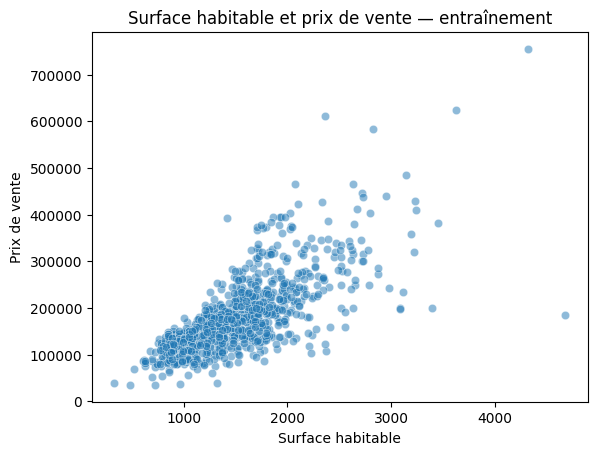

,GrLivArea,SalePrice,OverallQual,Neighborhood
421,4676,184750,10,Edwards
562,4316,755000,10,NoRidge
941,3627,625000,10,NoRidge
1023,3447,381000,8,Crawfor
518,3395,200000,6,SWISU


In [18]:
entrainement = X_train.assign(SalePrice=y_train)

sns.scatterplot(data=entrainement, x="GrLivArea", y="SalePrice", alpha=0.5)
plt.title("Surface habitable et prix de vente — entraînement")
plt.xlabel("Surface habitable")
plt.ylabel("Prix de vente")
plt.show()

display(
    entrainement.nlargest(5, "GrLivArea")[
        ["GrLivArea", "SalePrice", "OverallQual", "Neighborhood"]
    ]
)

In [27]:
correlations_spearman = X_train[colonnes_numeriques].corrwith(
    y_train, method="spearman"
)

tableau_correlations = (
    correlations_spearman
    .sort_values(ascending=False)
    .round(2)
    .to_frame(name="Corrélation de Spearman avec SalePrice")
)

display(tableau_correlations)

,Corrélation de Spearman avec SalePrice
OverallQual,0.81
GrLivArea,0.75
GarageCars,0.70
YearBuilt,0.66
GarageArea,0.66
FullBath,0.65
YearRemodAdd,0.60
TotalBsmtSF,0.60
1stFlrSF,0.59
TotRmsAbvGrd,0.55


In [19]:
correlations = X_train[colonnes_numeriques].corrwith(
    y_train, method="spearman"
)

display(correlations.sort_values(ascending=False).round(2))

OverallQual     0.81
GrLivArea       0.75
GarageCars      0.70
YearBuilt       0.66
GarageArea      0.66
FullBath        0.65
YearRemodAdd    0.60
TotalBsmtSF     0.60
1stFlrSF        0.59
TotRmsAbvGrd    0.55
Fireplaces      0.51
LotArea         0.47
dtype: float64

In [20]:
X_train_enrichi = X_train.assign(
    SurfaceQualite=X_train["GrLivArea"] * X_train["OverallQual"]
)

display(X_train_enrichi[["GrLivArea", "OverallQual", "SurfaceQualite"]].head())

,GrLivArea,OverallQual,SurfaceQualite
296,1287,5,6435
599,1349,7,9443
711,910,5,4550
274,1112,5,5560
362,1183,3,3549


In [22]:
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score

pretraitement_enrichi = ColumnTransformer([
    ("numerique", StandardScaler(), colonnes_numeriques + ["SurfaceQualite"]),
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
])

modele_enrichi = clone(modele_ridge).set_params(
    pretraitement=pretraitement_enrichi
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_reference = -cross_val_score(
    modele_ridge, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
)
scores_enrichis = -cross_val_score(
    modele_enrichi, X_train_enrichi, y_train, cv=cv, scoring="neg_mean_absolute_error"
)

print(f"MAE moyenne sans SurfaceQualite : {scores_reference.mean():.2f}")
print(f"MAE moyenne avec SurfaceQualite : {scores_enrichis.mean():.2f}")

MAE moyenne sans SurfaceQualite : 20345.07
MAE moyenne avec SurfaceQualite : 19428.21


/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.ve

In [23]:
colonnes_sans_garage_area = [
    colonne for colonne in colonnes_numeriques if colonne != "GarageArea"
] + ["SurfaceQualite"]

pretraitement_sans_garage_area = ColumnTransformer([
    ("numerique", StandardScaler(), colonnes_sans_garage_area),
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
])

modele_sans_garage_area = clone(modele_enrichi).set_params(
    pretraitement=pretraitement_sans_garage_area
)

scores_sans_garage_area = -cross_val_score(
    modele_sans_garage_area,
    X_train_enrichi,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    error_score="raise",
)

print(f"MAE avec GarageArea : {scores_enrichis.mean():.2f}")
print(f"MAE sans GarageArea : {scores_sans_garage_area.mean():.2f}")

MAE avec GarageArea : 19428.21
MAE sans GarageArea : 19468.42


/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.ve

In [24]:
comparaison_garage = pd.DataFrame(
    {
        "Avec GarageArea": scores_enrichis,
        "Sans GarageArea": scores_sans_garage_area,
    },
    index=range(1, 6),
)
comparaison_garage.index.name = "Découpage"
comparaison_garage["Écart (sans − avec)"] = (
    comparaison_garage["Sans GarageArea"] - comparaison_garage["Avec GarageArea"]
)

display(comparaison_garage.round(2))

,Avec GarageArea,Sans GarageArea,Écart (sans − avec)
Découpage,,,
1,17922.93,17984.30,61.37
2,20692.37,20791.57,99.20
3,19940.53,20024.05,83.52
4,20059.57,20132.85,73.28
5,18525.65,18409.31,-116.34


In [25]:
X_train_final = X_train_enrichi.drop(columns="GarageArea")

X_val_final = X_val.drop(columns="GarageArea").assign(
    SurfaceQualite=X_val["GrLivArea"] * X_val["OverallQual"]
)

modele_final = clone(modele_sans_garage_area)
modele_final.fit(X_train_final, y_train)

predictions_finales = modele_final.predict(X_val_final)
mae_finale = mean_absolute_error(y_val, predictions_finales)

print(f"MAE de Ridge initial sur la validation : {mae_ridge:.2f}")
print(f"MAE de la version retenue sur la validation : {mae_finale:.2f}")

MAE de Ridge initial sur la validation : 20936.76
MAE de la version retenue sur la validation : 19645.06


/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.venv/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/saidmohamedali/prediction-prix-immobilier/.ve

In [26]:
import numpy as np

X_val_prepare = modele_final.named_steps["pretraitement"].transform(X_val_final)
if hasattr(X_val_prepare, "toarray"):
    X_val_prepare = X_val_prepare.toarray()

ridge_final = modele_final.named_steps["regression"]
predictions_verifiees = (
    X_val_prepare * ridge_final.coef_
).sum(axis=1) + ridge_final.intercept_

print("Toutes les prédictions sont finies :", np.isfinite(predictions_finales).all())
print("Les deux calculs concordent :", np.allclose(predictions_finales, predictions_verifiees))

Toutes les prédictions sont finies : True
Les deux calculs concordent : True
